In [1]:

# Step 1: Import the required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

# Step 2: Load the student performance dataset

file_path = "data/Student Performance Factors.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


FileNotFoundError: [Errno 2] No such file or directory: 'data/Student Performance Factors.csv'

In [ ]:

# Step 3: Inspect the dataset structure

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)


Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             660

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,NaN,NaN,NaN,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,NaN,NaN,NaN,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Parental_Involvement,6607,3,Medium,3362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Access_to_Resources,6607,3,Medium,3319,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular_Activities,6607,2,Yes,3938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep_Hours,6607.0,NaN,NaN,NaN,7.02906,1.46812,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,NaN,NaN,NaN,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Motivation_Level,6607,3,Medium,3351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,6607,2,Yes,6108,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tutoring_Sessions,6607.0,NaN,NaN,NaN,1.493719,1.23057,0.0,1.0,1.0,2.0,8.0


In [ ]:

# Step 4: Check missing values

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary = missing_summary[missing_summary["Missing Values"] > 0]

print("Columns containing missing values:")
display(missing_summary.sort_values("Missing Values", ascending=False))


Columns containing missing values:


,Missing Values,Missing Percentage
Parental_Education_Level,90,1.362192
Teacher_Quality,78,1.180566
Distance_from_Home,67,1.014076


In [ ]:

# Step 5: Check duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print("Dataset shape before duplicate handling:", df.shape)


Number of duplicate rows: 0
Dataset shape before duplicate handling: (6607, 20)


In [ ]:

# Step 6: Inspect numerical ranges

numeric_columns = df.select_dtypes(include=np.number).columns

display(df[numeric_columns].describe().T)

# Inspect the unique values in categorical columns
categorical_columns = df.select_dtypes(exclude=np.number).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,1.493719,1.230570,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6607.0,2.967610,1.031231,0.0,2.0,3.0,4.0,6.0
Exam_Score,6607.0,67.235659,3.890456,55.0,65.0,67.0,69.0,101.0



Parental_Involvement:
Parental_Involvement
Medium    3362
High      1908
Low       1337
Name: count, dtype: int64

Access_to_Resources:
Access_to_Resources
Medium    3319
High      1975
Low       1313
Name: count, dtype: int64

Extracurricular_Activities:
Extracurricular_Activities
Yes    3938
No     2669
Name: count, dtype: int64

Motivation_Level:
Motivation_Level
Medium    3351
Low       1937
High      1319
Name: count, dtype: int64

Internet_Access:
Internet_Access
Yes    6108
No      499
Name: count, dtype: int64

Family_Income:
Family_Income
Low       2672
Medium    2666
High      1269
Name: count, dtype: int64

Teacher_Quality:
Teacher_Quality
Medium    3925
High      1947
Low        657
NaN         78
Name: count, dtype: int64

School_Type:
School_Type
Public     4598
Private    2009
Name: count, dtype: int64

Peer_Influence:
Peer_Influence
Positive    2638
Neutral     2592
Negative    1377
Name: count, dtype: int64

Learning_Disabilities:
Learning_Disabilities
No     5912
Yes

In [ ]:
print("Minimum exam score:", df["Exam_Score"].min())
print("Maximum exam score:", df["Exam_Score"].max())

Minimum exam score: 55
Maximum exam score: 101


In [ ]:

# Step 4: Check missing values

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary = missing_summary[missing_summary["Missing Values"] > 0]
missing_summary = missing_summary.sort_values(
    by="Missing Values", ascending=False
)

print("Columns containing missing values:")
display(missing_summary)


Columns containing missing values:


,Missing Values,Missing Percentage
Parental_Education_Level,90,1.362192
Teacher_Quality,78,1.180566
Distance_from_Home,67,1.014076


In [ ]:

# Step 5: Check duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [ ]:

# Step 6: Review numerical columns

numeric_columns = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(numeric_columns.tolist())

print("\nNumerical summary:")
display(df[numeric_columns].describe().T)


Numerical columns:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Exam_Score']

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,1.493719,1.230570,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6607.0,2.967610,1.031231,0.0,2.0,3.0,4.0,6.0
Exam_Score,6607.0,67.235659,3.890456,55.0,65.0,67.0,69.0,101.0


In [ ]:

# Step 7: Create a copy for data cleaning

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)



Original dataset shape: (6607, 20)
Working dataset shape: (6607, 20)


In [ ]:

# Step 8: Fill missing categorical values

categorical_missing_columns = [
    "Teacher_Quality",
    "Parental_Education_Level",
    "Distance_from_Home"
]

for column in categorical_missing_columns:
    mode_value = df_clean[column].mode(dropna=True)[0]
    df_clean[column] = df_clean[column].fillna(mode_value)

print("Missing values after filling:")
print(df_clean.isnull().sum().sum())


Missing values after filling:
0


In [ ]:

# Step 9: Remove duplicate records, if any

duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates().copy()

duplicates_after = df_clean.duplicated().sum()

print("Duplicates found:", duplicates_before)
print("Duplicates remaining:", duplicates_after)
print("Cleaned dataset shape:", df_clean.shape)


Duplicates found: 0
Duplicates remaining: 0
Cleaned dataset shape: (6607, 20)


In [ ]:

# Step 10: Investigate exam scores

print(df_clean["Exam_Score"].describe())

print("\nScores above 100:")
display(df_clean.loc[df_clean["Exam_Score"] > 100])

print("\nScores below 0:")
display(df_clean.loc[df_clean["Exam_Score"] < 0])


count    6607.000000
mean       67.235659
std         3.890456
min        55.000000
25%        65.000000
50%        67.000000
75%        69.000000
max       101.000000
Name: Exam_Score, dtype: float64

Scores above 100:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101



Scores below 0:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score


In [ ]:

# Step 11: Final data quality check

print("Final dataset shape:", df_clean.shape)
print("Total missing values:", df_clean.isnull().sum().sum())
print("Total duplicate rows:", df_clean.duplicated().sum())

display(df_clean.head())


Final dataset shape: (6607, 20)
Total missing values: 0
Total duplicate rows: 0


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:

# Step 12: Prepare visualization settings

from pathlib import Path

output_dir = Path("outputs/visualizations")
output_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

print("Visualization folder is ready!")


Visualization folder is ready!


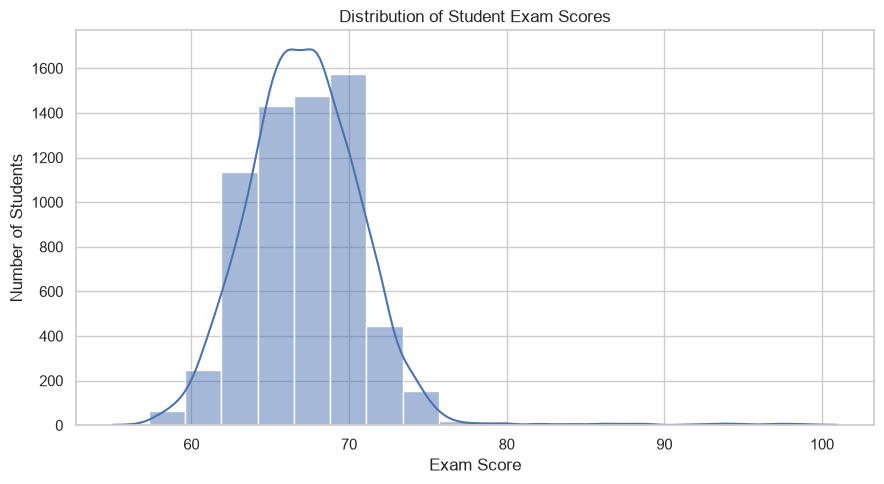

In [ ]:

# Chart 1: Distribution of exam scores

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="Exam_Score",
    bins=20,
    kde=True
)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")
plt.tight_layout()

plt.savefig(output_dir / "exam_score_distribution.png", dpi=300)
plt.show()


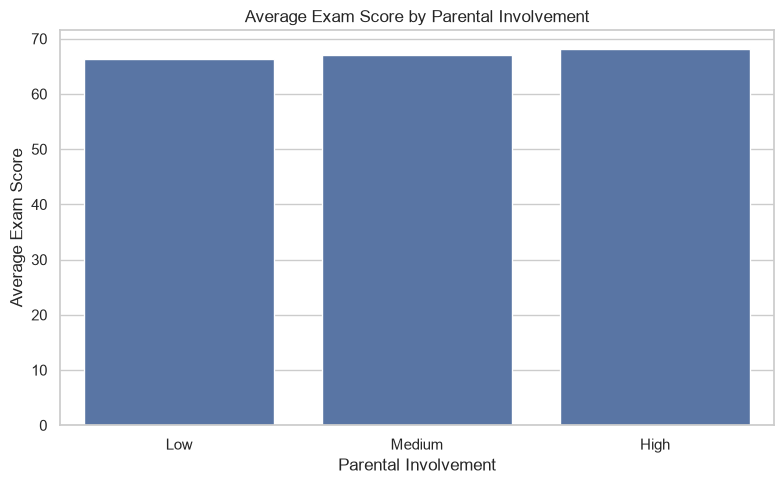

In [ ]:

# Chart 2: Average exam score by parental involvement

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="Parental_Involvement",
    y="Exam_Score",
    errorbar=None
)

plt.title("Average Exam Score by Parental Involvement")
plt.xlabel("Parental Involvement")
plt.ylabel("Average Exam Score")
plt.tight_layout()

plt.savefig(output_dir / "average_score_by_parental_involvement.png", dpi=300)
plt.show()


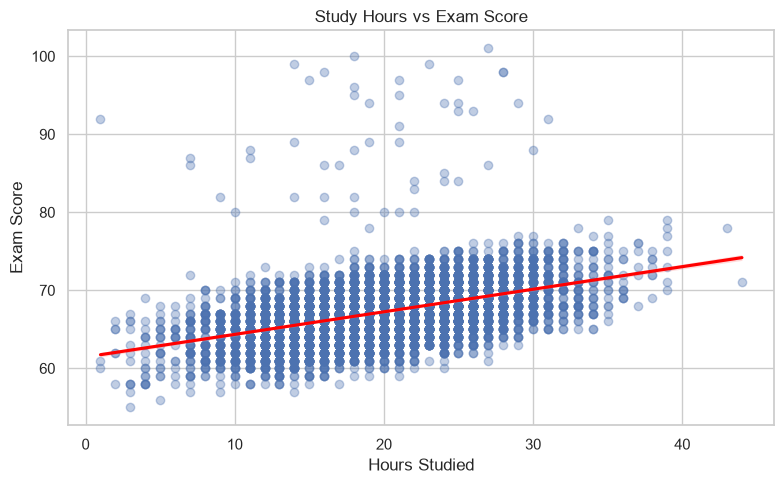

In [ ]:

# Chart 3: Study hours versus exam score

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_clean,
    x="Hours_Studied",
    y="Exam_Score",
    scatter_kws={"alpha": 0.35},
    line_kws={"color": "red"}
)

plt.title("Study Hours vs Exam Score")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.tight_layout()

plt.savefig(output_dir / "study_hours_vs_exam_score.png", dpi=300)
plt.show()


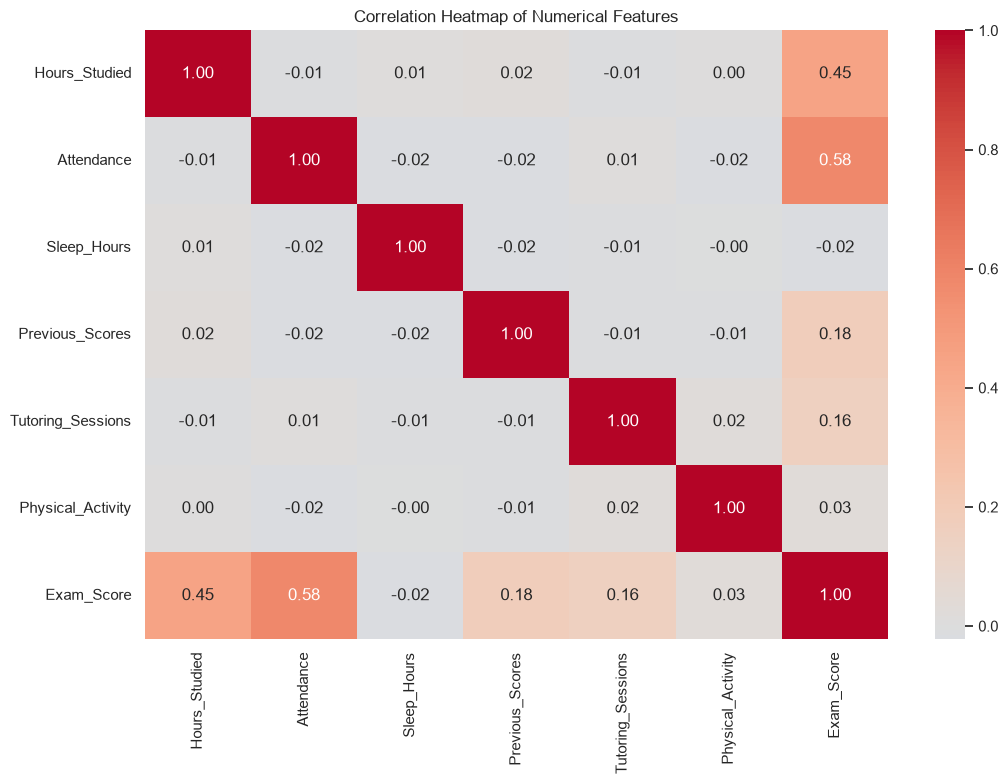

In [ ]:

# Chart 4: Correlation heatmap

numeric_df = df_clean.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()

plt.savefig(output_dir / "correlation_heatmap.png", dpi=300)
plt.show()


In [ ]:

# Check saved visualizations

saved_charts = list(output_dir.glob("*.png"))

print("Number of saved charts:", len(saved_charts))

for chart in saved_charts:
    print(chart)


Number of saved charts: 10
outputs\visualizations\actual_vs_predicted.png
outputs\visualizations\actual_vs_predicted_standalone.png
outputs\visualizations\attendance_vs_exam_score.png
outputs\visualizations\average_score_by_parental_involvement.png
outputs\visualizations\correlation_heatmap.png
outputs\visualizations\exam_score_boxplot.png
outputs\visualizations\exam_score_distribution.png
outputs\visualizations\prediction_error_distribution.png
outputs\visualizations\previous_scores_vs_exam_score.png
outputs\visualizations\study_hours_vs_exam_score.png


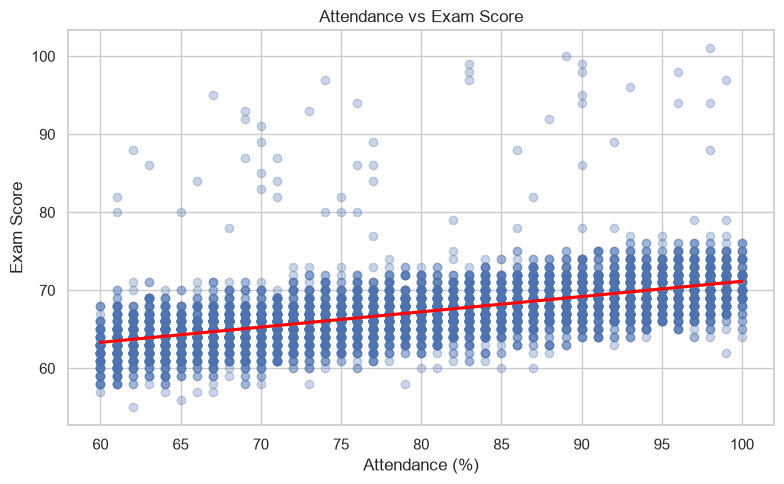

In [ ]:

# Chart 5: Attendance vs Exam Score

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_clean,
    x="Attendance",
    y="Exam_Score",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Attendance vs Exam Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Exam Score")
plt.tight_layout()

plt.savefig(output_dir / "attendance_vs_exam_score.png", dpi=300)
plt.show()


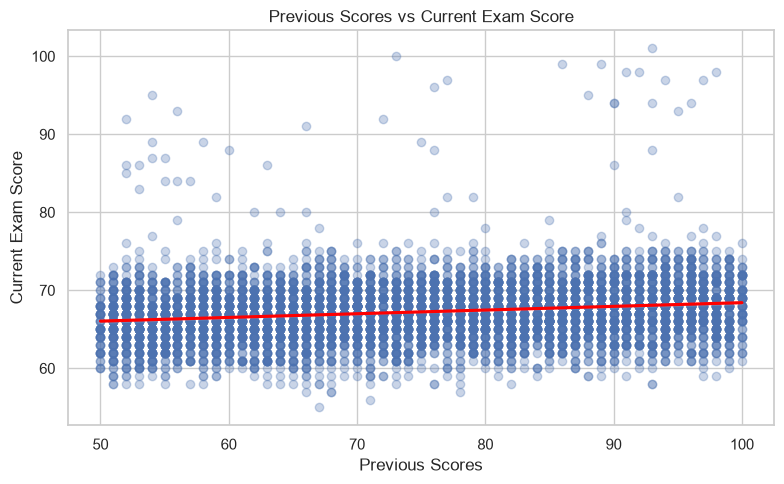

In [ ]:

# Chart 6: Previous Scores vs Exam Score

plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_clean,
    x="Previous_Scores",
    y="Exam_Score",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Previous Scores vs Current Exam Score")
plt.xlabel("Previous Scores")
plt.ylabel("Current Exam Score")
plt.tight_layout()

plt.savefig(output_dir / "previous_scores_vs_exam_score.png", dpi=300)
plt.show()


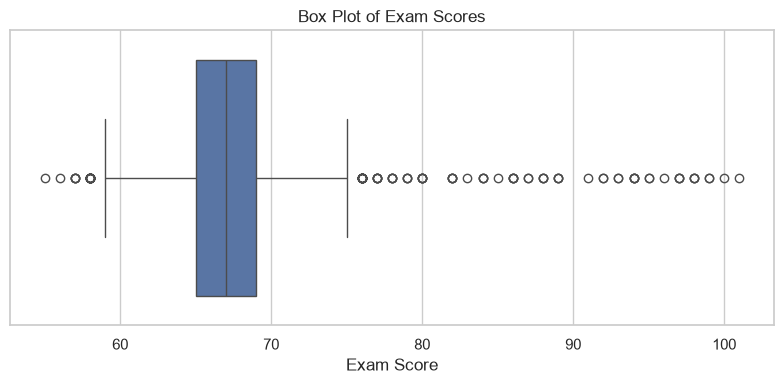

In [ ]:

# Chart 7: Exam score box plot

plt.figure(figsize=(8, 4))

sns.boxplot(data=df_clean, x="Exam_Score")

plt.title("Box Plot of Exam Scores")
plt.xlabel("Exam Score")
plt.tight_layout()

plt.savefig(output_dir / "exam_score_boxplot.png", dpi=300)
plt.show()


In [ ]:

from pathlib import Path

evaluation_dir = Path("outputs/evaluation_results")
evaluation_dir.mkdir(parents=True, exist_ok=True)

print("Evaluation results folder is ready!")


Evaluation results folder is ready!


In [ ]:

# Step 13: Descriptive statistics

summary_stats = df_clean[
    ["Hours_Studied", "Attendance", "Previous_Scores",
     "Sleep_Hours", "Tutoring_Sessions", "Exam_Score"]
].agg(["mean", "median", "std"]).T

summary_stats.columns = ["Mean", "Median", "Standard Deviation"]

display(summary_stats.round(2))

summary_stats.to_csv(
    "outputs/evaluation_results/descriptive_statistics.csv"
)

print("Descriptive statistics saved!")


,Mean,Median,Standard Deviation
Hours_Studied,19.98,20.0,5.99
Attendance,79.98,80.0,11.55
Previous_Scores,75.07,75.0,14.40
Sleep_Hours,7.03,7.0,1.47
Tutoring_Sessions,1.49,1.0,1.23
Exam_Score,67.24,67.0,3.89


Descriptive statistics saved!


In [ ]:

# Step 14: Rank correlations with Exam_Score

score_correlations = (
    numeric_df.corr()["Exam_Score"]
    .drop("Exam_Score")
    .sort_values(key=abs, ascending=False)
)

display(score_correlations.to_frame("Correlation with Exam_Score").round(3))


,Correlation with Exam_Score
Attendance,0.581
Hours_Studied,0.445
Previous_Scores,0.175
Tutoring_Sessions,0.157
Physical_Activity,0.028
Sleep_Hours,-0.017


In [ ]:

# Save descriptive statistics

summary_stats.to_csv(
    evaluation_dir / "descriptive_statistics.csv"
)

print("Descriptive statistics saved successfully!")


Descriptive statistics saved successfully!


In [ ]:

print("Saved file exists:",
      (evaluation_dir / "descriptive_statistics.csv").exists())


Saved file exists: True


In [ ]:

# Step 15: Select features and target variable

features = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Physical_Activity"
]

X = df_clean[features]
y = df_clean["Exam_Score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nSelected features:")
print(features)


Features shape: (6607, 6)
Target shape: (6607,)

Selected features:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']


In [ ]:

# Step 16: Split data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 5285
Testing records: 1322


In [ ]:

# Step 17: Train the Linear Regression model

from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [ ]:

# Step 18: Predict exam scores

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Exam Score": y_test.to_numpy(),
    "Predicted Exam Score": y_pred
})

display(results.head(10))


,Actual Exam Score,Predicted Exam Score
0,65,66.090430
1,65,67.255843
2,71,68.445187
3,64,66.765869
4,66,65.652394
5,66,68.032063
6,72,70.157618
7,66,67.330727
8,70,68.902635
9,70,67.942167


In [ ]:

# Step 19: Evaluate model performance

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.3f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f}")
print(f"R-squared (R²): {r2:.3f}")


Mean Absolute Error (MAE): 1.266
Root Mean Squared Error (RMSE): 2.251
R-squared (R²): 0.642


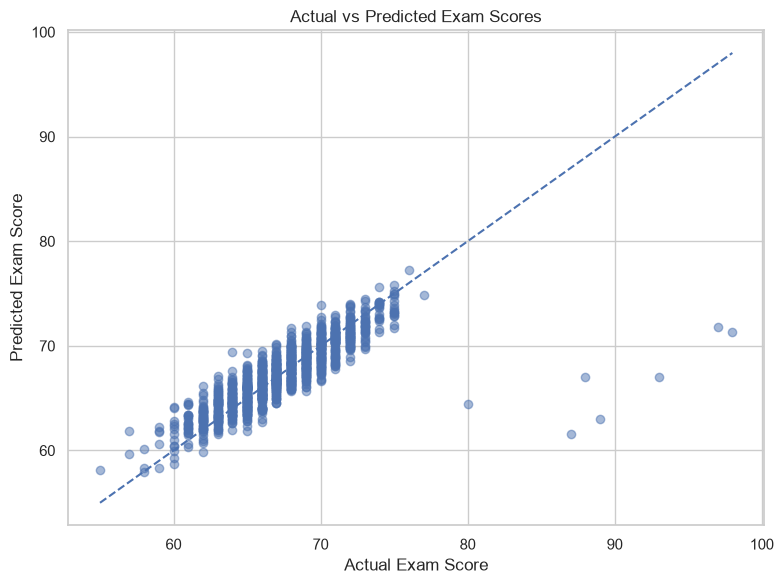

In [ ]:

# Step 20: Actual vs Predicted Exam Scores

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Ideal predictions lie on this diagonal line
min_score = min(y_test.min(), y_pred.min())
max_score = max(y_test.max(), y_pred.max())

plt.plot(
    [min_score, max_score],
    [min_score, max_score],
    linestyle="--"
)

plt.title("Actual vs Predicted Exam Scores")
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.tight_layout()

plt.savefig(
    output_dir / "actual_vs_predicted.png",
    dpi=300
)

plt.show()


In [ ]:

# Step 21: Five-fold cross-validation

from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

cv_mae_scores = -cross_val_score(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

print("MAE for each fold:", np.round(cv_mae_scores, 3))
print(f"Mean CV MAE: {cv_mae_scores.mean():.3f}")
print(f"Standard deviation: {cv_mae_scores.std():.3f}")


MAE for each fold: [1.298 1.344 1.256 1.369 1.367]
Mean CV MAE: 1.327
Standard deviation: 0.044


In [ ]:

# Step 22: Save evaluation metrics

evaluation_dir = Path("outputs/evaluation_results")
evaluation_dir.mkdir(parents=True, exist_ok=True)

metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2", "Mean CV MAE", "CV MAE Std"],
    "Value": [
        mae,
        rmse,
        r2,
        cv_mae_scores.mean(),
        cv_mae_scores.std()
    ]
})

display(metrics_df.round(4))

metrics_df.to_csv(
    evaluation_dir / "model_evaluation_metrics.csv",
    index=False
)

print("Evaluation metrics saved successfully!")


,Metric,Value
0,MAE,1.2659
1,RMSE,2.2507
2,R2,0.6416
3,Mean CV MAE,1.3268
4,CV MAE Std,0.0436


Evaluation metrics saved successfully!


In [ ]:

# Step 23: Export predictions

results = pd.DataFrame({
    "Actual_Exam_Score": y_test.to_numpy(),
    "Predicted_Exam_Score": y_pred
})

results["Absolute_Error"] = (
    results["Actual_Exam_Score"] - results["Predicted_Exam_Score"]
).abs()

results.to_csv(
    evaluation_dir / "actual_vs_predicted_results.csv",
    index=False
)

print("Prediction results saved successfully!")


Prediction results saved successfully!


In [ ]:

# Step 24: Save the trained model

import joblib

model_path = Path("src/student_performance_model.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(model, model_path)

print("Trained model saved to:", model_path)


Trained model saved to: src\student_performance_model.joblib


In [ ]:

# Step 25: Analyze prediction errors

error_analysis = pd.DataFrame({
    "Actual_Score": y_test.to_numpy(),
    "Predicted_Score": y_pred
})

error_analysis["Error"] = (
    error_analysis["Actual_Score"] -
    error_analysis["Predicted_Score"]
)

error_analysis["Absolute_Error"] = error_analysis["Error"].abs()

print("Prediction error summary:")
display(error_analysis[["Error", "Absolute_Error"]].describe().round(3))

print("\nFive largest prediction errors:")
display(
    error_analysis.nlargest(5, "Absolute_Error").round(2)
)


Prediction error summary:


,Error,Absolute_Error
count,1322.000,1322.000
mean,0.002,1.266
std,2.252,1.862
min,-5.431,0.001
25%,-1.092,0.457
50%,-0.088,1.001
75%,0.897,1.680
max,26.658,26.658



Five largest prediction errors:


,Actual_Score,Predicted_Score,Error,Absolute_Error
704,98,71.34,26.66,26.66
1144,93,67.00,26.00,26.00
28,89,63.05,25.95,25.95
1125,87,61.61,25.39,25.39
721,97,71.81,25.19,25.19


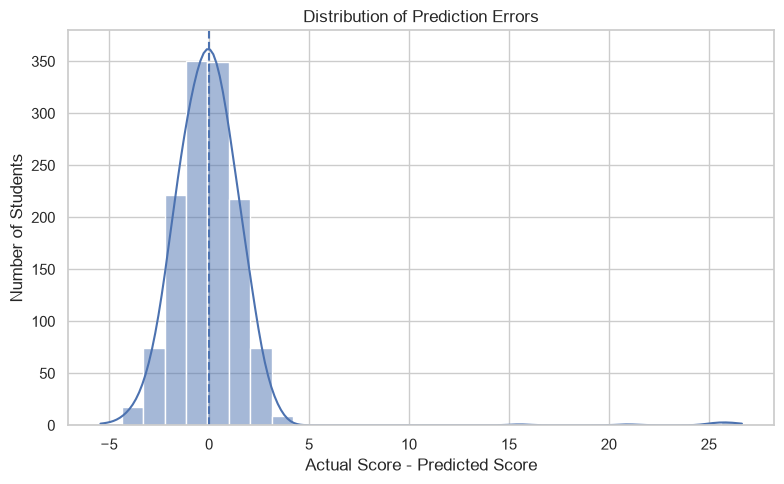

In [ ]:

# Chart 8: Distribution of prediction errors

plt.figure(figsize=(8, 5))

sns.histplot(error_analysis["Error"], bins=30, kde=True)

plt.axvline(0, linestyle="--")
plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Score - Predicted Score")
plt.ylabel("Number of Students")
plt.tight_layout()

plt.savefig(output_dir / "prediction_error_distribution.png", dpi=300)
plt.show()


In [ ]:

# Step 26: Compare Linear Regression and Ridge Regression

from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge())
])

parameter_grid = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Ridge parameters:", grid_search.best_params_)
print(f"Best cross-validation MAE: {-grid_search.best_score_:.3f}")


Best Ridge parameters: {'regressor__alpha': 0.01}
Best cross-validation MAE: 1.327


In [ ]:

# Step 27: Evaluate the tuned Ridge model

ridge_best = grid_search.best_estimator_
ridge_pred = ridge_best.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))
ridge_r2 = r2_score(y_test, ridge_pred)

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Tuned Ridge Regression"],
    "MAE": [mae, ridge_mae],
    "RMSE": [rmse, ridge_rmse],
    "R2": [r2, ridge_r2]
})

display(comparison.round(4))


,Model,MAE,RMSE,R2
0,Linear Regression,1.2659,2.2507,0.6416
1,Tuned Ridge Regression,1.2659,2.2507,0.6416


In [ ]:

# Step 28: Save model comparison results

evaluation_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    evaluation_dir / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")


Model comparison saved successfully!


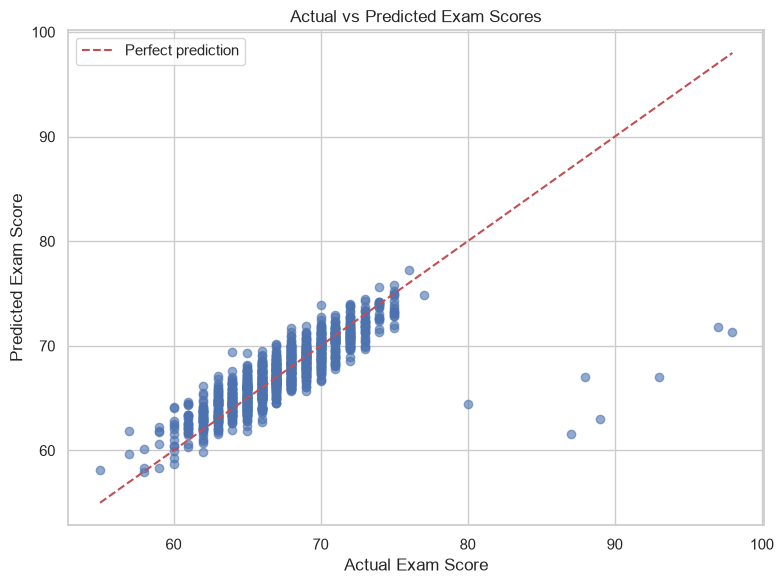

Graph saved to: outputs\visualizations\actual_vs_predicted_standalone.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

results_path = Path("outputs/evaluation_results/standalone_predictions.csv")
output_path = Path("outputs/visualizations/actual_vs_predicted_standalone.png")

if not results_path.exists():
    print("Prediction file not found. Run src/model.py successfully first.")
else:
    results = pd.read_csv(results_path)

    plt.figure(figsize=(8, 6))
    plt.scatter(
        results["Actual_Exam_Score"],
        results["Predicted_Exam_Score"],
        alpha=0.6
    )

    lower = min(
        results["Actual_Exam_Score"].min(),
        results["Predicted_Exam_Score"].min()
    )
    upper = max(
        results["Actual_Exam_Score"].max(),
        results["Predicted_Exam_Score"].max()
    )

    plt.plot([lower, upper], [lower, upper], "r--", label="Perfect prediction")
    plt.xlabel("Actual Exam Score")
    plt.ylabel("Predicted Exam Score")
    plt.title("Actual vs Predicted Exam Scores")
    plt.legend()
    plt.tight_layout()

    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"Graph saved to: {output_path}")

Notebook location: c:\Users\Lenovo\Desktop\project1
Reading predictions from: c:\Users\Lenovo\Desktop\project1\outputs\evaluation_results\standalone_predictions.csv


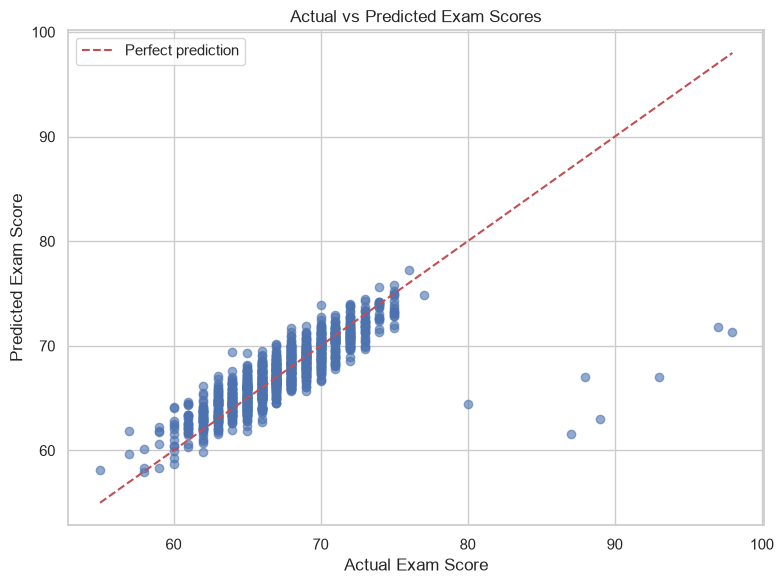

Graph saved to: c:\Users\Lenovo\Desktop\project1\outputs\visualizations\actual_vs_predicted_standalone.png


In [ ]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the project folder
current_dir = Path.cwd()

if (current_dir / "outputs").exists():
    project_dir = current_dir
elif (current_dir.parent / "outputs").exists():
    project_dir = current_dir.parent
else:
    raise FileNotFoundError(
        "Could not find the project outputs folder. "
        f"Notebook location: {current_dir}"
    )

results_path = (
    project_dir / "outputs" / "evaluation_results"
    / "standalone_predictions.csv"
)
output_path = (
    project_dir / "outputs" / "visualizations"
    / "actual_vs_predicted_standalone.png"
)

print("Notebook location:", current_dir)
print("Reading predictions from:", results_path)

if not results_path.exists():
    raise FileNotFoundError(f"Prediction file not found: {results_path}")

results = pd.read_csv(results_path)

plt.figure(figsize=(8, 6))
plt.scatter(
    results["Actual_Exam_Score"],
    results["Predicted_Exam_Score"],
    alpha=0.6
)

lower = min(
    results["Actual_Exam_Score"].min(),
    results["Predicted_Exam_Score"].min()
)
upper = max(
    results["Actual_Exam_Score"].max(),
    results["Predicted_Exam_Score"].max()
)

plt.plot(
    [lower, upper], [lower, upper],
    "r--", label="Perfect prediction"
)
plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Exam Scores")
plt.legend()
plt.tight_layout()

output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graph saved to:", output_path)


In [ ]:
from pathlib import Path
import pandas as pd

metrics_path = (
    Path.cwd() / "outputs" / "evaluation_results"
    / "standalone_model_metrics.csv"
)

if not metrics_path.exists():
    metrics_path = (
        Path.cwd().parent / "outputs" / "evaluation_results"
        / "standalone_model_metrics.csv"
    )

metrics = pd.read_csv(metrics_path)
display(metrics.round(3))

,MAE,RMSE,R2,Best_Alpha,CV_MAE
0,1.266,2.251,0.642,0.01,1.327


In [ ]:

from pathlib import Path
import joblib
import pandas as pd

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "src").exists():
    PROJECT_DIR = PROJECT_DIR.parent

MODEL_PATH = PROJECT_DIR / "src" / "student_performance_model.joblib"

print("Project folder:", PROJECT_DIR)
print("Model exists:", MODEL_PATH.exists())

FEATURES = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Physical_Activity",
]


def main():
    if not MODEL_PATH.exists():
        print("Trained model not found. Run src/model.py first.")
        return

    model = joblib.load(MODEL_PATH)

    print("\nSTUDENT EXAM SCORE PREDICTOR")
    print("-" * 32)

    student = {
        "Hours_Studied": float(input("Study hours per day: ")),
        "Attendance": float(input("Attendance percentage (0-100): ")),
        "Sleep_Hours": float(input("Sleep hours per day: ")),
        "Previous_Scores": float(input("Previous exam score: ")),
        "Tutoring_Sessions": float(input("Tutoring sessions per month: ")),
        "Physical_Activity": float(input("Physical activity hours per week: ")),
    }

    student_df = pd.DataFrame([student], columns=FEATURES)
    predicted_score = float(model.predict(student_df)[0])

    print("\nPredicted exam score:", round(predicted_score, 2))
    print(
        "Note: This is an estimate from a machine-learning model, "
        "not a guaranteed result."
    )


if __name__ == "__main__":
    main()




Project folder: c:\Users\Lenovo\Desktop\project1
Model exists: True

STUDENT EXAM SCORE PREDICTOR
--------------------------------



Predicted exam score: 63.5
Note: This is an estimate from a machine-learning model, not a guaranteed result.


In [ ]:
from pathlib import Path

project_dir = Path.cwd()

if not (project_dir / "src").exists():
    project_dir = project_dir.parent

model_path = project_dir / "src" / "student_performance_model.joblib"

print("Project directory:", project_dir)
print("Model file exists:", model_path.exists())

Project directory: c:\Users\Lenovo\Desktop\project1
Model file exists: True


In [ ]:
from pathlib import Path
import joblib
import sys
import joblib

print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

project_dir = Path.cwd()

if not (project_dir / "src").exists():
    project_dir = project_dir.parent

model_path = project_dir / "src" / "student_performance_model.joblib"
model = joblib.load(model_path)

print("Model reloaded successfully.")

Python: c:\Users\Lenovo\Desktop\project1\.venv\Scripts\python.exe


NameError: name 'sklearn' is not defined

In [ ]:
import sys
import sklearn

print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__)

In [ ]:
import sys
import sklearn

print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__)

Python: c:\Users\Lenovo\Desktop\project1\.venv\Scripts\python.exe
scikit-learn: 1.9.1


In [ ]:
from pathlib import Path
import joblib
import pandas as pd

project_dir = Path.cwd()
if not (project_dir / "src").exists():
    project_dir = project_dir.parent

model_path = project_dir / "src" / "student_performance_model.joblib"
model = joblib.load(model_path)

sample_student = pd.DataFrame([{
    "Hours_Studied": 3,
    "Attendance": 90,
    "Sleep_Hours": 8,
    "Previous_Scores": 75,
    "Tutoring_Sessions": 2,
    "Physical_Activity": 4
}])

prediction = model.predict(sample_student)[0]
print(f"Predicted exam score: {prediction:.2f}")

Predicted exam score: 64.69


In [ ]:
import pandas as pd
import joblib
from pathlib import Path

# Load the trained model
project_dir = Path.cwd()

if not (project_dir / "src").exists():
    project_dir = project_dir.parent

model_path = project_dir / "src" / "student_performance_model.joblib"
model = joblib.load(model_path)

# Prediction function
def predict_student(hours_studied, attendance, sleep_hours,
                    previous_scores, tutoring_sessions,
                    physical_activity):

    student_data = pd.DataFrame([{
        "Hours_Studied": hours_studied,
        "Attendance": attendance,
        "Sleep_Hours": sleep_hours,
        "Previous_Scores": previous_scores,
        "Tutoring_Sessions": tutoring_sessions,
        "Physical_Activity": physical_activity
    }])

    prediction = model.predict(student_data)[0]

    return round(float(prediction), 2)


# Test with sample student
score = predict_student(
    hours_studied=3,
    attendance=90,
    sleep_hours=8,
    previous_scores=75,
    tutoring_sessions=2,
    physical_activity=4
)

print("Predicted Exam Score:", score)

Predicted Exam Score: 64.69


In [ ]:
students = [
    {
        "Student": "Student 1",
        "Hours_Studied": 2,
        "Attendance": 70,
        "Sleep_Hours": 6,
        "Previous_Scores": 55,
        "Tutoring_Sessions": 1,
        "Physical_Activity": 2
    },
    {
        "Student": "Student 2",
        "Hours_Studied": 5,
        "Attendance": 95,
        "Sleep_Hours": 8,
        "Previous_Scores": 85,
        "Tutoring_Sessions": 3,
        "Physical_Activity": 5
    },
    {
        "Student": "Student 3",
        "Hours_Studied": 4,
        "Attendance": 85,
        "Sleep_Hours": 7,
        "Previous_Scores": 70,
        "Tutoring_Sessions": 2,
        "Physical_Activity": 3
    }
]

prediction_results = []

for student in students:
    score = predict_student(
        student["Hours_Studied"],
        student["Attendance"],
        student["Sleep_Hours"],
        student["Previous_Scores"],
        student["Tutoring_Sessions"],
        student["Physical_Activity"]
    )

    prediction_results.append({
        "Student": student["Student"],
        "Predicted_Exam_Score": score
    })

prediction_df = pd.DataFrame(prediction_results)
display(prediction_df)

,Student,Predicted_Exam_Score
0,Student 1,58.72
1,Student 2,67.41
2,Student 3,63.63


In [ ]:
output_path = (
    project_dir / "outputs" / "evaluation_results"
    / "sample_student_predictions.csv"
)

prediction_df.to_csv(output_path, index=False)

print("Predictions saved:", output_path)

Predictions saved: c:\Users\Lenovo\Desktop\project1\outputs\evaluation_results\sample_student_predictions.csv
